In [1]:
import logging
logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
    kamada_kawai_layout ,
)

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_atom, is_superatomic

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# Linear PAAm homopolymer

In [2]:
num_mols : int = 4
DOP : int = 10

## Assemble MuPT repr

In [3]:
lexicon = {
    'head' : primitive_from_smiles('[H:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]'),
    'mid'  : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]'),
    'tail' : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[H:2]'),
}

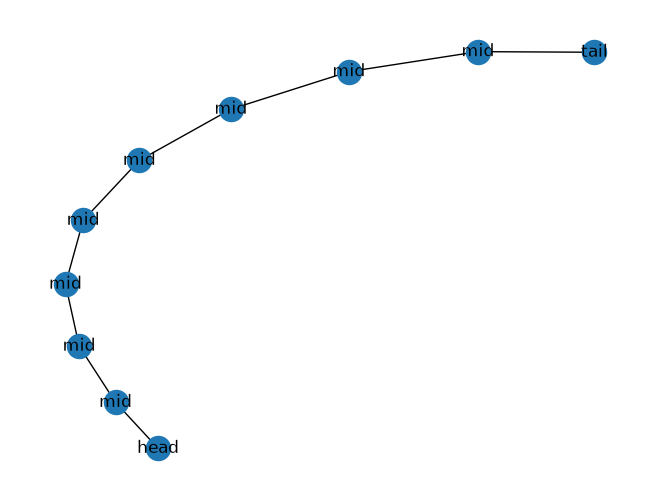

In [4]:
from networkx import get_node_attributes, connected_components
from mupt.graphs.generators import path_graph_from_sequence


label_attr : str = 'label'
sequence_graph = path_graph_from_sequence(
    ['head'] + (DOP - 2)*['mid'] + ['tail'],
    label_attr=label_attr,
)

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, label_attr),
)

### Select, connect, then inspect

In [5]:
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim.parent, CompositePrimitive)
# predicate : NodePredicate[Primitive] = is_superatomic
predicate : NodePredicate[Primitive] = is_atom

In [6]:
molprim_prototype = CompositePrimitive()
molprim_prototype.populate_from_topology_and_lexicon(
    sequence_graph,
    lexicon,
    label_attr=label_attr,
)

system = RootPrimitive(label='system')
for i in range(num_mols):
    molprim = molprim_prototype.copy()
    molprim.label = f'molecule_{i}'
    system.attach_child(molprim)

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


In [7]:
xsec = system.cross_section(predicate)
print(f'{len(list(connected_components(xsec)))} molecules')

4 molecules


<Axes: >

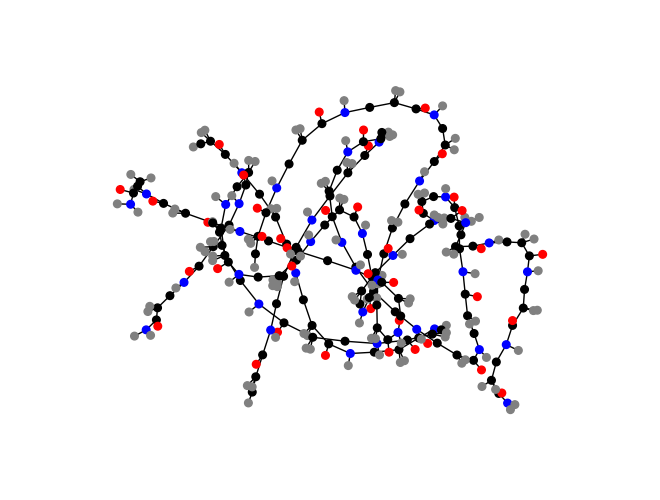

In [8]:
pos = spring_layout(xsec, dim=2)
system.visualize_cross_section(xsec, pos=pos, with_labels=False, node_size=30)

## Export to mbuild

In [9]:
compound = primitive_to_mbuild(
    system,
    predicate=predicate,
    # set False (default) to have Particles directly on Compound
    preserve_intermediates=True, 
)
... # insert downstream code here
print(compound)

<system 328 particles, 324 bonds, non-periodic, id: 126836448210976>


In [10]:
# inspect direct descendants of "root" Compound which is returned
display(set(subcomp.name for subcomp in compound.children))

{'molecule_0', 'molecule_1', 'molecule_2', 'molecule_3'}

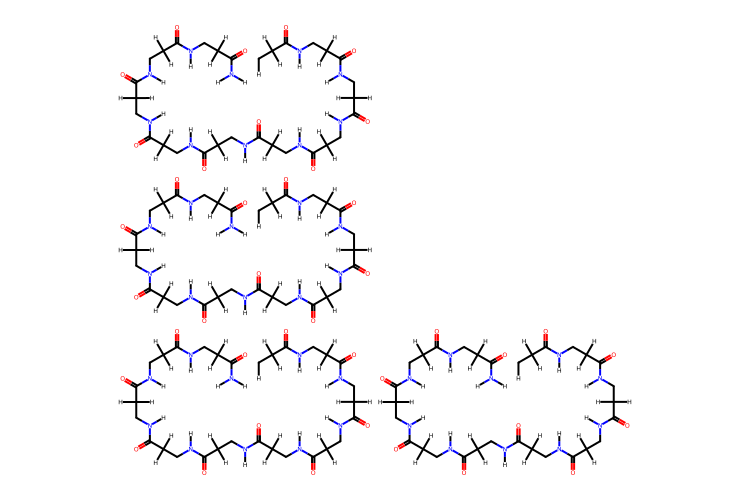

In [11]:
from mupt.chemistry.rdkit.depiction import set_rdkdraw_size, hide_atom_indices

set_rdkdraw_size(500, 3/2)
hide_atom_indices()

mols = compound.to_rdkit()
for atom in mols.GetAtoms():
    atom.ClearProp('atomLabel')
display(mols)

# PAMAM dendrimer

In [ ]:
print(molprim.hierarchy_summary())

## Assemble MuPT repr

In [ ]:
num_generations : int = 3
lexicon={ # notice the values are Primitive instances; applied even if not all-atom
    'cyanogen' : primitive_from_smiles("[N:1](-[*:2])(-[*:2])CC[N:1](-[*:2])(-[*:2])", label='cyanogen'),
    'AAm'      : primitive_from_smiles("[*:1]-[C:2]C(=O)NCC[N:1](-[*:2])(-[*:2])", label='AAm'),
    'AAm_T'    : primitive_from_smiles("[*:1]-[C:2]C(=O)NCC[NH2]", label='AAm_T'),
}

In [ ]:
from networkx import nx_agraph
from mupt.graphs.generators import balanced_dendrimer_graph


dendr = balanced_dendrimer_graph(
    coord_number=(lexicon['AAm'].functionality - 1),
    coord_number_core=lexicon['cyanogen'].functionality,
    num_generations=num_generations,
    core='cyanogen',
    shell_inner='AAm',
    shell_outer='AAm_T',
)

nx_draw(
    dendr,
    pos=nx_agraph.graphviz_layout(dendr, prog='twopi'),
    with_labels=True,
    labels=get_node_attributes(dendr, 'label'),
)

### Select, connect, then inspect

In [ ]:
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim, CompositePrimitive)
predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
# predicate : NodePredicate[Primitive] = is_atom

In [ ]:
molprim = RootPrimitive()
molprim.populate_from_topology_and_lexicon(dendr, lexicon, label_attr='label')

# predicate = lambda prim: prim.parent is molprim
predicate = lambda prim: prim.label in lexicon
xsec = molprim.cross_section(predicate)

print(f'{len(list(connected_components(xsec)))} molecules')


In [ ]:
# NOTE: this is the rate-limiting step here; not actually necessary for
# system setup, only for embedding nice-to-look-at positions.
# Will eventually be replaced w/ rigid/random walk initial coord gen
pos = kamada_kawai_layout(xsec, dim=2)

In [ ]:
molprim.visualize_cross_section(
    xsec, pos=pos,
    with_labels=True, 
    node_size=10,
    labels=get_node_attributes(xsec, 'label')
)

## Export to mbuild

In [ ]:
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

compound = primitive_to_mbuild(molprim, predicate=predicate)
... # insert downstream code here
print(compound)